# 04 — Neural upgrade (exploratory follow-up)

The original FD001 test results were known before this work. Selection uses validation only, but the test comparison below is **descriptive and not independent confirmation**. Original coursework artifacts are retained. This notebook reads saved results only.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUT = ROOT / 'experiments' / 'neural_upgrade'
FIG = OUT / 'figures'
FIG.mkdir(exist_ok=True)
read = lambda name: json.loads((OUT / name).read_text())
result, selection, search = read('test_results.json'), read('selection.json'), read('search_results.json')
comparison = pd.read_csv(OUT / 'comparison.csv')
print('Selected architecture:', selection['selected_config'])
print('Trainable parameters:', selection['runs'][0]['parameters'])
print('All scores use capped RUL (125 cycles); test engines =', result['n_test_engines'])

Selected architecture: {'name': 'pooled_regularised', 'architecture': 'feature_mlp', 'representation': 'pooled', 'hidden': [128, 64], 'dropout': 0.1, 'weight_decay': 0.001}
Trainable parameters: 26369
All scores use capped RUL (125 cycles); test engines = 100


## Fixed search and selection

Eight candidates × two tuning seeds; no test score used to rank candidates. The final winner adds seed 2. All trials, including the weaker CNNs, are retained.

In [2]:
trials = pd.DataFrame([{'candidate': r['config']['name'], 'architecture': r['config']['architecture'], 'seed 0 val RMSE': r['seed_results'][0]['val_rmse'], 'seed 1 val RMSE': r['seed_results'][1]['val_rmse'], 'mean val RMSE': r['mean_val_rmse']} for r in search])
display(trials.sort_values('mean val RMSE').round(4))

,candidate,architecture,seed 0 val RMSE,seed 1 val RMSE,mean val RMSE
4,pooled_regularised,feature_mlp,12.1683,12.1200,12.1442
3,pooled_wide,feature_mlp,12.2483,12.2201,12.2342
1,summary_wide,feature_mlp,12.2591,12.2225,12.2408
2,pooled_small,feature_mlp,12.2286,12.3198,12.2742
0,summary_small,feature_mlp,12.2689,12.3340,12.3015
5,cnn_small,temporal_cnn,13.1067,12.7237,12.9152
6,cnn_wide,temporal_cnn,13.0824,13.0370,13.0597
7,cnn_regularised,temporal_cnn,13.1236,13.0450,13.0843


## Selected model

Each 30 × 14 input becomes 140 train-standardised features: 56 summary features plus 84 ordered five-cycle means. The neural network is 140 → 128 (SiLU, dropout 0.1) → 64 (SiLU, dropout 0.1) → 1 (sigmoid) × 125. Training uses MSE, AdamW, validation learning-rate reduction and early stopping. The sigmoid bounds predictions between zero and the cap; it does not guarantee true remaining life.

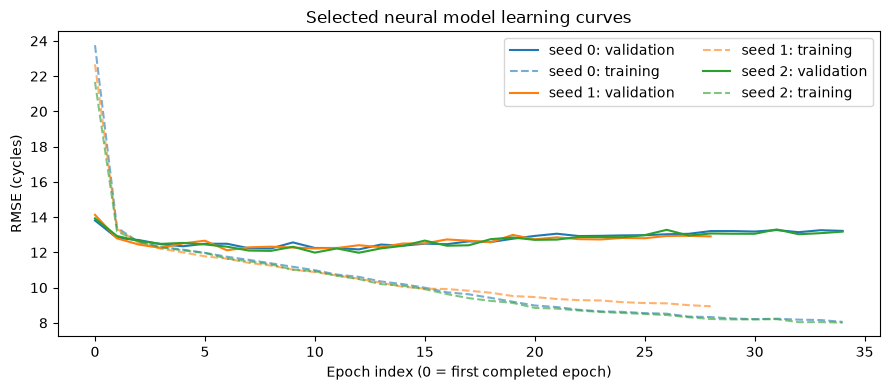

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
for seed in result['seeds']:
    record = read(f"{selection['selected_config']['name']}_seed{seed}.json")
    line, = ax.plot(np.sqrt(record['history']['val_mse']) * 125, label=f'seed {seed}: validation')
    ax.plot(np.sqrt(record['history']['train_mse']) * 125, '--', color=line.get_color(), alpha=.6, label=f'seed {seed}: training')
ax.set(xlabel='Epoch index (0 = first completed epoch)', ylabel='RMSE (cycles)', title='Selected neural model learning curves')
ax.legend(ncol=2); fig.tight_layout(); fig.savefig(FIG / 'learning_curves.png', dpi=150); plt.show()

## Individual runs and fair ensemble comparisons

Mean ± sample SD is calculated across three separately evaluated seeds. The CLI instead averages the three models' predictions. Every comparator has a matching three-model ensemble below.

,model,seed,val_rmse,test_rmse,test_mae,test_nasa_score
0,random_forest,0,12.8230,12.2502,9.0124,232.8079
1,random_forest,1,12.7626,11.9936,8.9018,220.1263
2,random_forest,2,12.7747,12.1344,9.0339,226.2034
3,mlp,0,12.7921,13.5543,9.9727,287.3521
4,mlp,1,12.8244,13.7396,10.3507,295.4473
5,mlp,2,12.8176,12.8994,9.8289,260.6363
6,lstm,0,12.9402,13.3607,9.9110,292.3739
7,lstm,1,12.7277,13.6415,10.0968,288.6060
8,lstm,2,12.8096,12.8007,9.4319,259.5651
9,neural_upgrade,0,12.1683,12.7529,9.6686,272.1891


,val RMSE mean,test RMSE mean,test RMSE SD,test MAE mean,ensemble test RMSE,ensemble inference ms (batch 1)
random_forest,12.7868,12.1261,0.1285,8.9827,12.1096,186.8667
mlp,12.8114,13.3978,0.4414,10.0507,13.1656,0.2309
lstm,12.8258,13.2676,0.4281,9.8132,13.1340,0.8518
neural_upgrade,12.0895,12.6903,0.1970,9.6443,12.5839,0.3514


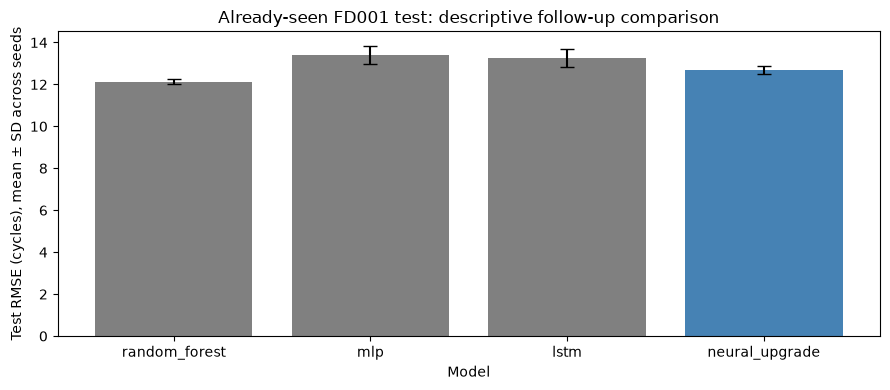

In [4]:
display(comparison.round(4))
summary = pd.DataFrame({name: {'val RMSE mean': v['val_rmse']['mean'], 'test RMSE mean': v['test_rmse']['mean'], 'test RMSE SD': v['test_rmse']['std'], 'test MAE mean': v['test_mae']['mean'], 'ensemble test RMSE': v['ensemble_test']['rmse'], 'ensemble inference ms (batch 1)': v['ensemble_inference_ms_batch1']} for name, v in result['models'].items()}).T
display(summary.round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(summary.index, summary['test RMSE mean'], yerr=summary['test RMSE SD'], capsize=5, color=['gray','gray','gray','steelblue'])
ax.set(xlabel='Model', ylabel='Test RMSE (cycles), mean ± SD across seeds', title='Already-seen FD001 test: descriptive follow-up comparison')
fig.tight_layout(); fig.savefig(FIG / 'comparison.png', dpi=150); plt.show()

## Prediction errors

The five largest errors are for the selected three-seed ensemble. Positive residuals overestimate remaining life. These examples do not guide any additional tuning.

,unit,true_rul,capped_rul,neural_upgrade_ensemble,error
66,67,77.0,77.0,113.67,36.67
44,45,114.0,114.0,83.89,-30.11
78,79,63.0,63.0,91.79,28.79
26,27,66.0,66.0,94.60,28.60
11,12,124.0,124.0,95.53,-28.47


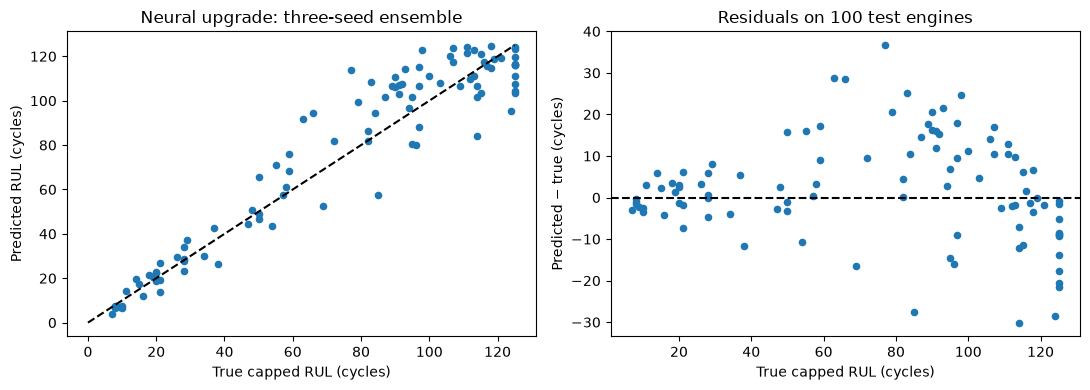

In [5]:
pred = pd.read_csv(OUT / 'test_predictions.csv')
pred['error'] = pred['neural_upgrade_ensemble'] - pred['capped_rul']
display(pred.loc[pred.error.abs().nlargest(5).index, ['unit','true_rul','capped_rul','neural_upgrade_ensemble','error']].round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(pred.capped_rul, pred.neural_upgrade_ensemble, s=20)
axes[0].plot([0,125], [0,125], 'k--'); axes[0].set(xlabel='True capped RUL (cycles)', ylabel='Predicted RUL (cycles)', title='Neural upgrade: three-seed ensemble')
axes[1].scatter(pred.capped_rul, pred.error, s=20); axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(xlabel='True capped RUL (cycles)', ylabel='Predicted − true (cycles)', title='Residuals on 100 test engines')
fig.tight_layout(); fig.savefig(FIG / 'prediction_errors.png', dpi=150); plt.show()

## Interpretation

The upgraded neural model reduced mean test RMSE from the old MLP's 13.40 to 12.69 cycles (5.3% lower RMSE). It also beat the old LSTM (13.27), but the forest remains better (12.13). No claim of beating all models is supported.

Changes in features, output bounds, activation and optimiser were made together; an ablation would be needed to identify the source of improvement. The old test set is reused and the validation set has seen additional tuning, so new independent evaluation is required. This follow-up should be disclosed separately from the original fixed-budget coursework.

Inference: `python scripts/predict.py examples/engine_normal.csv --model neural_upgrade`